<h2><font color="#004D7F" size=6>Módulo 3. Procesamiento de datos</font></h2>



<h1><font color="#004D7F" size=5>2. Transformación de datos</font></h1>


---

<h2><font color="#004D7F" size=5>Índice</font></h2>
<a id="indice"></a>

* [1. Introducción](#section1)
    * [1.1. Librerías y CSV](#section11)
* [2. Transformaciones](#section2)
    * [2.1. Escalamiento](#section21)
    * [2.2. Estandarización](#section22)
    * [2.3. Normalización](#section23)
    * [2.4. Binarización](#section24)
    * [2.5. Box-Cox](#section25)
    * [2.6. Yeo-Johnson](#section26)

<a id="section1"></a>
# <font color="#004D7F"> 1. Introducción</font>

Los datos en bruto, sin analizar de antemano, muy difícilmente nos va a dar precisiones robustas ya que, entre otros aspectos, muchos de ellos requieren los datos en una forma específica, por lo que deberemos realizar una transformación del conjunto de datos. Por otro lado, otros algoritmos pueden funcionar mejor si los datos se preparan de una manera específica, por ejemplo, los de tipo árbol con atributos característica de tipo nominal. Por tanto, es de vital importancia realizar un preprocesamiento a nuestro datos como parte fundamental de realizar un proyecto de machine learning.

<a id="section11"></a>
## <font color="#004D7F"> 1.1. Librerías y CSV</font>

Para esta práctica vamos a cargar el conjunto de datos de Pima Indian Diabetes y trabajar diferentes tipos de transformaciones de datos. Así mismo, en algunas de ellas vamos a trabajar otros conjuntos de datos para ver un mejor impacto en su transformación.

Por otro lado, en cuanto a las librerías, vamos a ver llamarlas según cada transformación. Tenga en cuenta que estas trasnformaciónes vamos a trabajarlas con la librería **Scikit-learn**.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
filename = "../data/pima-indians-diabetes.csv"
names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
data = pd.read_csv(filename, names=names)
array = data.values
# separate array into input and output components
X = array[:,0:8]
Y = array[:,8]

*Se importa el dataset y se separa*
array[:, :] → todas las filas y todas las columnas.
array[:, 0:8] → todas las filas, columnas de la 0 a la 7.
array[:, 8] → todas las filas, solo la columna 8.
array[0:5, :] → filas de la 0 a la 4, todas las columnas.
array[3, :] → la fila 3 completa.

<div style="text-align: right"> <font size=5>
    <a href="#indice"><i class="fa fa-arrow-circle-up" aria-hidden="true" style="color:#004D7F"></i></a>
</font></div>

---

<a id="section2"></a>
## <font color="#004D7F"> 2. Transformaciones</font>

El método de ajuste y transformación múltiple es el enfoque preferido. Llama a la función `fit()` para preparar los parámetros de la transformación una vez en sus datos. Luego, puede usar la función `transform()` en los mismos datos para prepararlos para el modelado y nuevamente en el conjunto de datos de prueba o validación o los nuevos datos que puede ver en el futuro. El ajuste y transformación combinados es una conveniencia que puede usar para tareas únicas. Esto puede ser útil si está interesado en trazar o resumir los datos transformados y se utilizará la función `fit_transform()`. Puede revisar la API [**sklearn.preprocessing**](https://scikit-learn.org/stable/modules/classes.html#module-sklearn.preprocessing). Como puede verse existe una gran cantidad de funciones que podemos aplicar en esta fase de preprocesamiento según la necesidad de nuestros datos.

Es importante ver como quedan los datos antes y después de transformarlos. En el siguiente código puede ver como quedan los datos originales y comparlos con cada transformación.

<Axes: xlabel='age', ylabel='Count'>

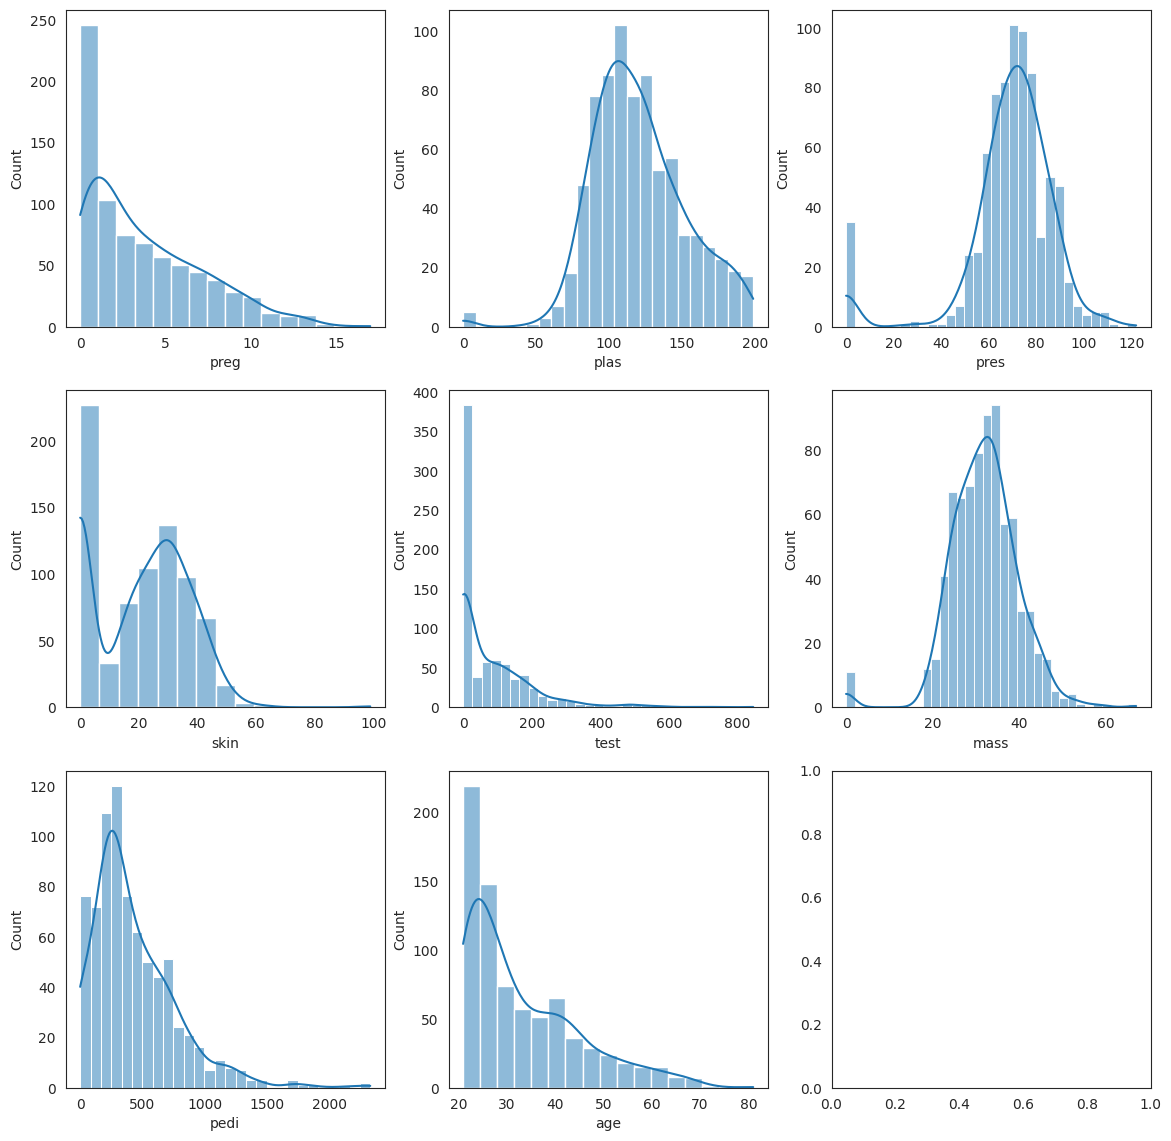

In [48]:
# Univariate Histograms
import matplotlib.pyplot as plt
import seaborn as sns
f, axes = plt.subplots(3, 3, figsize=(14, 14))
sns.histplot(data["preg"], ax=axes[0, 0], kde=True)
sns.histplot(data["plas"], ax=axes[0, 1], kde=True)
sns.histplot(data["pres"], ax=axes[0, 2], kde=True)
sns.histplot(data["skin"], ax=axes[1, 0], kde=True)
sns.histplot(data["test"], ax=axes[1, 1], kde=True)
sns.histplot(data["mass"], ax=axes[1, 2], kde=True)
sns.histplot(data["pedi"], ax=axes[2, 0], kde=True)
sns.histplot(data["age"], ax=axes[2, 1], kde=True)
# sns.histplot(data["class"], ax=axes[2, 2], kde=True)

Muestra los histogramas, la mayoria tiene picos en la parte derecha o en la parte de en medio, en la mayoria de datos hay diferencia o dispersion entre variables 

<a id="section21"></a>
## <font color="#004D7F"> 2.1. Escalamiento</font>

Esta transformación es útil para los algoritmos de optimización utilizados en el núcleo de los algoritmos de aprendizaje automático como Gradiente Descendiente. También es útil para algoritmos que ponderan entradas como Regression y Neural Networks y algoritmos que usan medidas de distancia como _k_-Nearest Neighbours. Puede reescalar sus datos usando la clase [MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html). 

Después de reescalar puede ver que todos los valores están en el rango $[0,1]$,

In [6]:
from numpy import set_printoptions
from sklearn.preprocessing import MinMaxScaler

# Rescale data (between 0 and 1) , crea el escalador y ajustarlo/transformar datos
scaler = MinMaxScaler(feature_range=(0, 1))
rescaledX = scaler.fit_transform(X)
# summarize transformed data
set_printoptions(precision=3)
print(rescaledX[0:5, :])

[[0.353 0.744 0.59  0.354 0.    0.501 0.269 0.483]
 [0.059 0.427 0.541 0.293 0.    0.396 0.151 0.167]
 [0.471 0.92  0.525 0.    0.    0.347 0.289 0.183]
 [0.059 0.447 0.541 0.232 0.111 0.419 0.072 0.   ]
 [0.    0.688 0.328 0.354 0.199 0.642 0.982 0.2  ]]


*MinMaxScaler* -> re-escala las variables para que ahora esten entre 0-1, tambien hay otras opciones de escalado;
-MinMaxScaler → (0 a 1) → bueno cuando no hay muchos outliers (valores atipicos) 
-StandardScaler → media=0, desviación=1 → el más usado
-RobustScaler → recomendado si tienes muchos outliers

In [7]:
# Convertimos el Numpy Array a dataframe
df_rescaled = pd.DataFrame(rescaledX, columns=names[0:8])
df_rescaled

,preg,plas,pres,skin,test,mass,pedi,age
0,0.352941,0.743719,0.590164,0.353535,0.000000,0.500745,0.269183,0.483333
1,0.058824,0.427136,0.540984,0.292929,0.000000,0.396423,0.150672,0.166667
2,0.470588,0.919598,0.524590,0.000000,0.000000,0.347243,0.288505,0.183333
3,0.058824,0.447236,0.540984,0.232323,0.111111,0.418778,0.071665,0.000000
4,0.000000,0.688442,0.327869,0.353535,0.198582,0.642325,0.982395,0.200000
...,...,...,...,...,...,...,...,...
763,0.588235,0.507538,0.622951,0.484848,0.212766,0.490313,0.073382,0.700000
764,0.117647,0.613065,0.573770,0.272727,0.000000,0.548435,0.000103,0.100000
765,0.294118,0.608040,0.590164,0.232323,0.132388,0.390462,0.105157,0.150000
766,0.058824,0.633166,0.491803,0.000000,0.000000,0.448584,0.149813,0.433333


los datos escalados que estan en un arreglo de numpy ahora se convierten en un dataframe 
rescaledX o X_scaled -> datos escalados

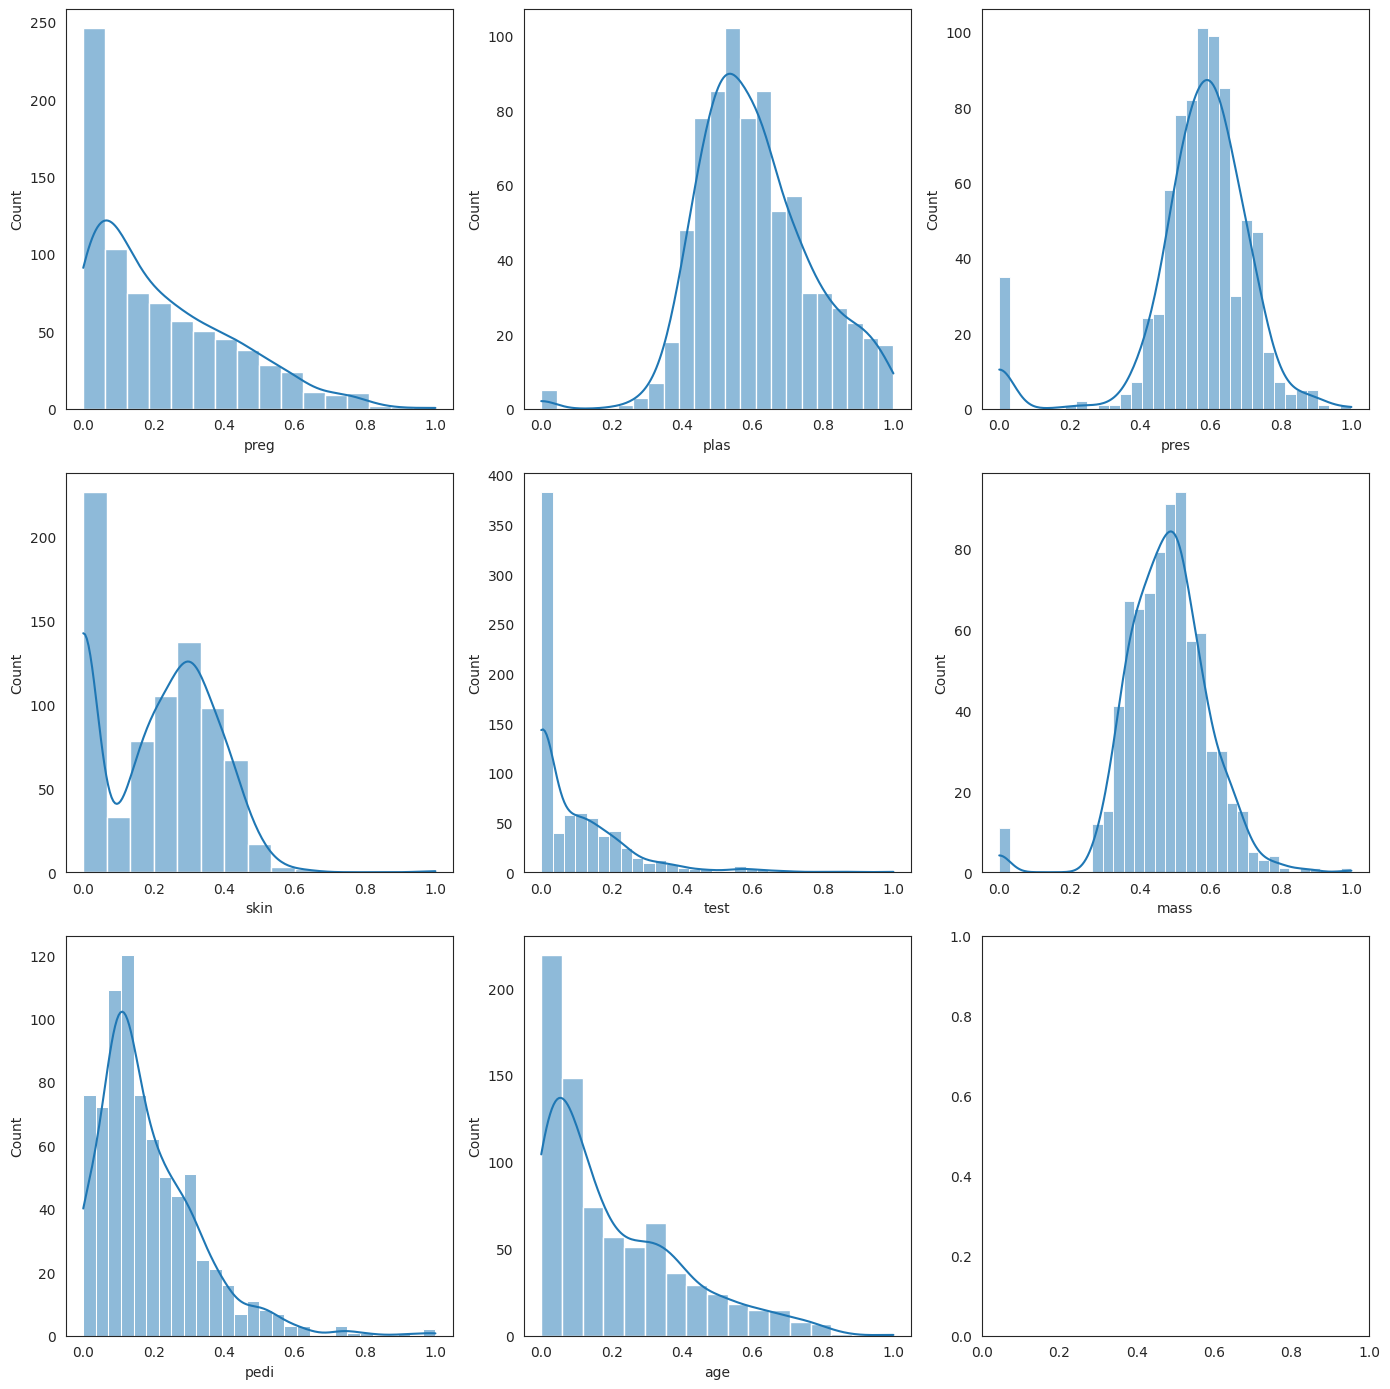

In [13]:
transform_df = pd.DataFrame(rescaledX, columns=names[0:8])

f, axes = plt.subplots(3, 3, figsize=(14, 14))

sns.histplot(transform_df["preg"], kde=True, ax=axes[0, 0])
sns.histplot(transform_df["plas"], kde=True, ax=axes[0, 1])
sns.histplot(transform_df["pres"], kde=True, ax=axes[0, 2])
sns.histplot(transform_df["skin"], kde=True, ax=axes[1, 0])
sns.histplot(transform_df["test"], kde=True, ax=axes[1, 1])
sns.histplot(transform_df["mass"], kde=True, ax=axes[1, 2])
sns.histplot(transform_df["pedi"], kde=True, ax=axes[2, 0])
sns.histplot(transform_df["age"], kde=True, ax=axes[2, 1])

plt.tight_layout()
plt.show()

Muestra el mismo conjuto de valores, pero ahora con datos escalados, eje x (0 a 1) & eje y (des 0 hasta 400) 

<a id="section22"></a>
## <font color="#004D7F"> 2.2. Estandarización</font>

Es más adecuada para técnicas que asumen una distribución gaussiana en las variables de entrada y funcionan mejor con datos reescalados, como Linear Regression, Logistic Regression y Linear Discriminant Analysis. Puede estandarizar datos utilizando la clase [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html). Los valores para cada atributo ahora tienen un valor medio de $0$ y una desviación estándar de $1$

In [14]:
from sklearn.preprocessing import StandardScaler

# Standardize data (0 mean, 1 stdev)
scaler = StandardScaler().fit(X)
rescaledX = scaler.transform(X)
# summarize transformed data
set_printoptions(precision=3)
print(rescaledX[0:5, :])

[[ 0.64   0.848  0.15   0.907 -0.693  0.204  0.584  1.426]
 [-0.845 -1.123 -0.161  0.531 -0.693 -0.684 -0.227 -0.191]
 [ 1.234  1.944 -0.264 -1.288 -0.693 -1.103  0.716 -0.106]
 [-0.845 -0.998 -0.161  0.155  0.123 -0.494 -0.768 -1.042]
 [-1.142  0.504 -1.505  0.907  0.766  1.41   5.466 -0.02 ]]


Muestra una matriz de numpy, pero ahora usa la funcion StandScaler, menos sensible, es el mas recomendado en la mayoria de casos

In [15]:
# Convertimos el Numpy Array a dataframe
transform_df = pd.DataFrame(rescaledX, columns=names[0:8])
transform_df

,preg,plas,pres,skin,test,mass,pedi,age
0,0.639947,0.848324,0.149641,0.907270,-0.692891,0.204013,0.584149,1.425995
1,-0.844885,-1.123396,-0.160546,0.530902,-0.692891,-0.684422,-0.226986,-0.190672
2,1.233880,1.943724,-0.263941,-1.288212,-0.692891,-1.103255,0.716400,-0.105584
3,-0.844885,-0.998208,-0.160546,0.154533,0.123302,-0.494043,-0.767743,-1.041549
4,-1.141852,0.504055,-1.504687,0.907270,0.765836,1.409746,5.465654,-0.020496
...,...,...,...,...,...,...,...,...
763,1.827813,-0.622642,0.356432,1.722735,0.870031,0.115169,-0.755987,2.532136
764,-0.547919,0.034598,0.046245,0.405445,-0.692891,0.610154,-1.257539,-0.531023
765,0.342981,0.003301,0.149641,0.154533,0.279594,-0.735190,-0.538509,-0.275760
766,-0.844885,0.159787,-0.470732,-1.288212,-0.692891,-0.240205,-0.232864,1.170732


se hace lo mismo que la vez anterior, convertir el arreglo en una dataframe

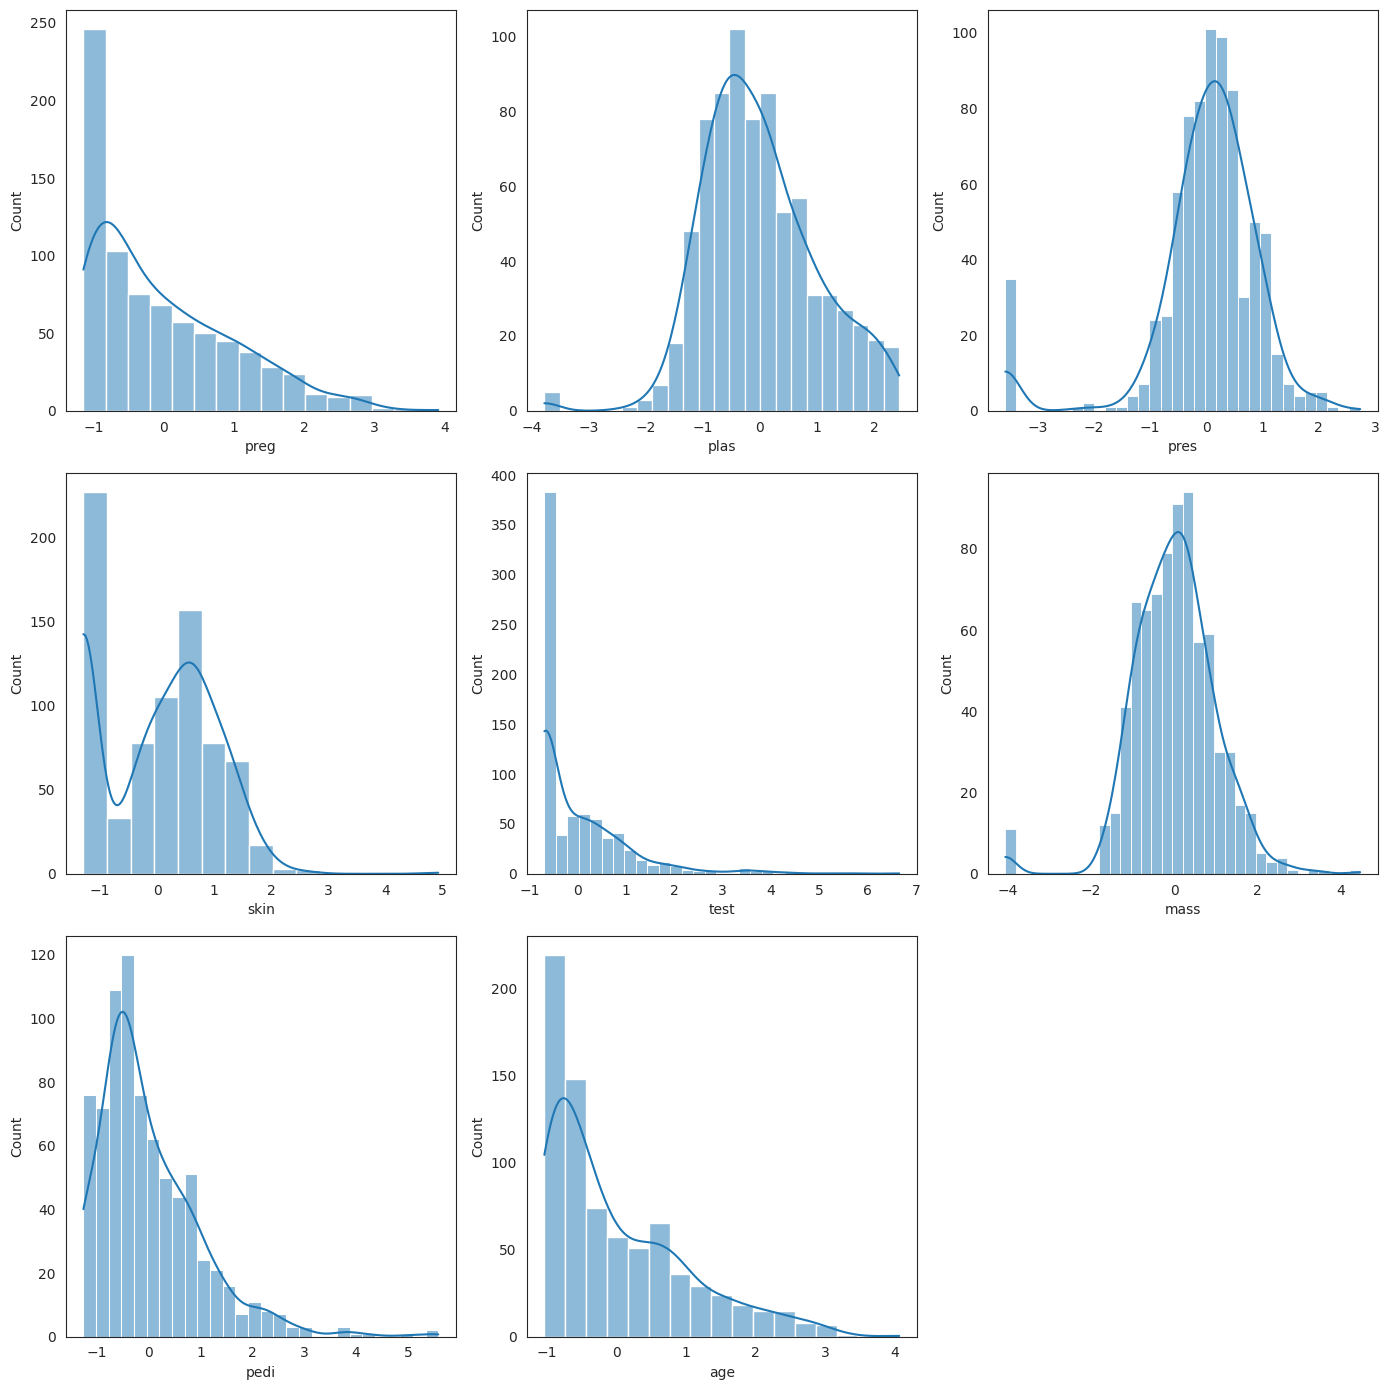

In [16]:
f, axes = plt.subplots(3, 3, figsize=(14, 14))

sns.histplot(transform_df["preg"], kde=True, ax=axes[0, 0])
sns.histplot(transform_df["plas"], kde=True, ax=axes[0, 1])
sns.histplot(transform_df["pres"], kde=True, ax=axes[0, 2])
sns.histplot(transform_df["skin"], kde=True, ax=axes[1, 0])
sns.histplot(transform_df["test"], kde=True, ax=axes[1, 1])
sns.histplot(transform_df["mass"], kde=True, ax=axes[1, 2])
sns.histplot(transform_df["pedi"], kde=True, ax=axes[2, 0])
sns.histplot(transform_df["age"], kde=True, ax=axes[2, 1])

axes[2, 2].axis('off')  # oculta el subplot vacío (9no espacio sin usar)

plt.tight_layout()
plt.show()

Los histogramas son muy similares a los anteriores, sin embargo ahora no va de (0-1) si no que de negativos (-4, -3, -1) a positivos (2,3,4,5)

<a id="section23"></a>
## <font color="#004D7F"> 2.3. Normalización</font>

Este método de preprocesamiento puede ser útil para conjuntos de datos dispersos (muchos ceros) con atributos de escalas variables cuando se utilizan algoritmos que ponderan valores de entrada como Neural Networks y algoritmos que usan medidas de distancia como k-Nearest Neighbours.

Puede normalizar datos en Python con la clase [Normalizer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.Normalizer.html). Las filas están normalizadas a la longitud $1$

In [17]:
# Normalize data (length of 1)
from sklearn.preprocessing import Normalizer

scaler = Normalizer().fit(X)
normalizedX = scaler.transform(X)
# summarize transformed data
set_printoptions(precision=3)
print(normalizedX[0:5, :])

[[0.009 0.227 0.11  0.054 0.    0.052 0.962 0.077]
 [0.003 0.229 0.178 0.078 0.    0.072 0.947 0.084]
 [0.011 0.261 0.091 0.    0.    0.033 0.959 0.046]
 [0.004 0.395 0.293 0.102 0.417 0.125 0.741 0.093]
 [0.    0.06  0.017 0.015 0.073 0.019 0.995 0.014]]


Normaliza los datos, utiliza la funcion Normalizer(), transforma cada fila, en la cual cada fila debe de ser = 1 

In [19]:
# Convertimos el Numpy Array a dataframe
transform_df = pd.DataFrame(normalizedX, columns=names[0:8])
transform_df

,preg,plas,pres,skin,test,mass,pedi,age
0,0.009202,0.226993,0.110429,0.053681,0.000000,0.051534,0.961653,0.076687
1,0.002699,0.229401,0.178123,0.078266,0.000000,0.071789,0.947291,0.083664
2,0.011419,0.261215,0.091354,0.000000,0.000000,0.033259,0.959217,0.045677
3,0.004438,0.395019,0.292935,0.102084,0.417211,0.124719,0.741216,0.093207
4,0.000000,0.059578,0.017395,0.015221,0.073059,0.018743,0.994998,0.014351
...,...,...,...,...,...,...,...,...
763,0.034285,0.346278,0.260565,0.164568,0.617128,0.112797,0.586272,0.215995
764,0.013304,0.811526,0.465629,0.179600,0.000000,0.244788,0.002262,0.179600
765,0.016262,0.393541,0.234173,0.074805,0.364270,0.085213,0.796840,0.097572
766,0.002632,0.331587,0.157899,0.000000,0.000000,0.079212,0.918443,0.123687


convierte el arreglo en un dataframe

<Axes: xlabel='age', ylabel='Count'>

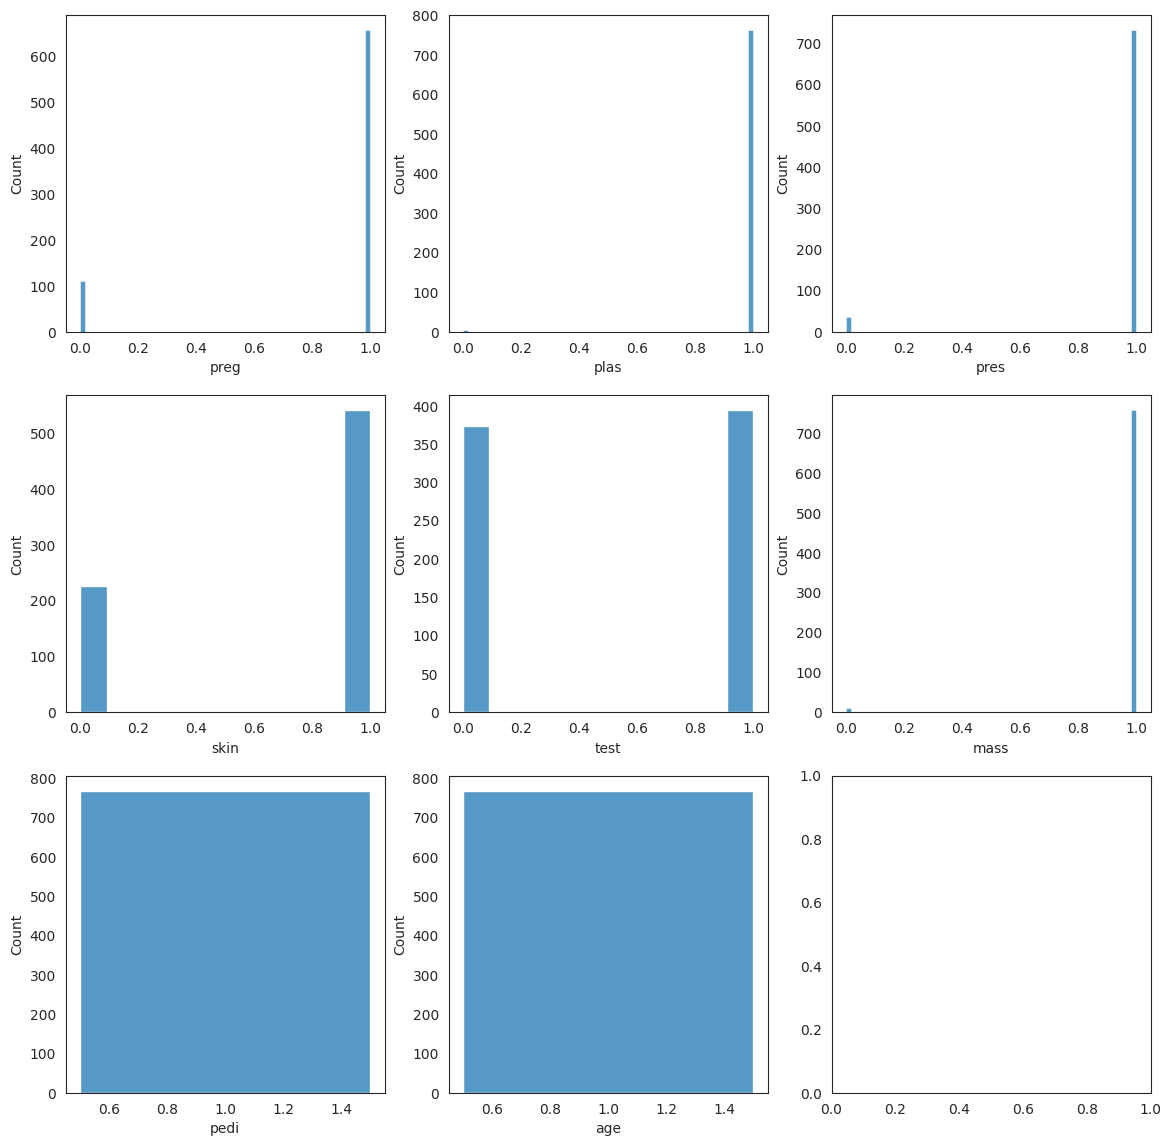

In [42]:

f, axes = plt.subplots(3, 3, figsize=(14, 14))
sns.histplot(transform_df["preg"], ax=axes[0, 0])
sns.histplot(transform_df["plas"], ax=axes[0, 1])
sns.histplot(transform_df["pres"], ax=axes[0, 2])
sns.histplot(transform_df["skin"], ax=axes[1, 0])
sns.histplot(transform_df["test"], ax=axes[1, 1])
sns.histplot(transform_df["mass"], ax=axes[1, 2])
sns.histplot(transform_df["pedi"], ax=axes[2, 0])
sns.histplot(transform_df["age"], ax=axes[2, 1])

En este caso al representar, es notable la alteracion de los datos, pierde la forma original de los datos, eso significa que no es un buen escalador para este tipo de dataset 

<a id="section24"></a>
## <font color="#004D7F"> 2.4. Binarización</font>

Puede crear nuevos atributos binarios en Python usando la clase [Binarizer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.Normalizer.html). Puede ver que todos los valores iguales o menores que 0 están marcados con 0 y todos los que están por encima de 0 están marcados con 1.

In [20]:
# binarization
from sklearn.preprocessing import Binarizer

binarizer = Binarizer(threshold=0.0).fit(X)
binaryX = binarizer.transform(X)

# summarize transformed data
set_printoptions(precision=3)
print(binaryX[0:5, :])

[[1. 1. 1. 1. 0. 1. 1. 1.]
 [1. 1. 1. 1. 0. 1. 1. 1.]
 [1. 1. 1. 0. 0. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [0. 1. 1. 1. 1. 1. 1. 1.]]


Convierte los valores en 0 & 1, ideal para datos que tienen dos salidas true/false, si/no diabetes/no diabetes, sin embargo la mayoria de variables son continuas, no es conveniente aplicar binarizer()

In [ ]:
# Convertir el Numpy Array a dataframe
transform_df = pd.DataFrame(binaryX, columns=names[0:8])
transform_df

,preg,plas,pres,skin,test,mass,pedi,age
0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0
1,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0
2,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0
3,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
...,...,...,...,...,...,...,...,...
763,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
764,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0
765,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
766,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0


se convierte el arreglo a dataframe

In [26]:
print(transform_df.head())
print(transform_df["preg"].unique()) 

   preg  plas  pres  skin  test  mass  pedi  age
0   1.0   1.0   1.0   1.0   0.0   1.0   1.0  1.0
1   1.0   1.0   1.0   1.0   0.0   1.0   1.0  1.0
2   1.0   1.0   1.0   0.0   0.0   1.0   1.0  1.0
3   1.0   1.0   1.0   1.0   1.0   1.0   1.0  1.0
4   0.0   1.0   1.0   1.0   1.0   1.0   1.0  1.0
[1. 0.]


se imprime la variable preg (embarazos) y tambien muestra todos los valores posible (1 || 0 )

<Axes: xlabel='age', ylabel='Count'>

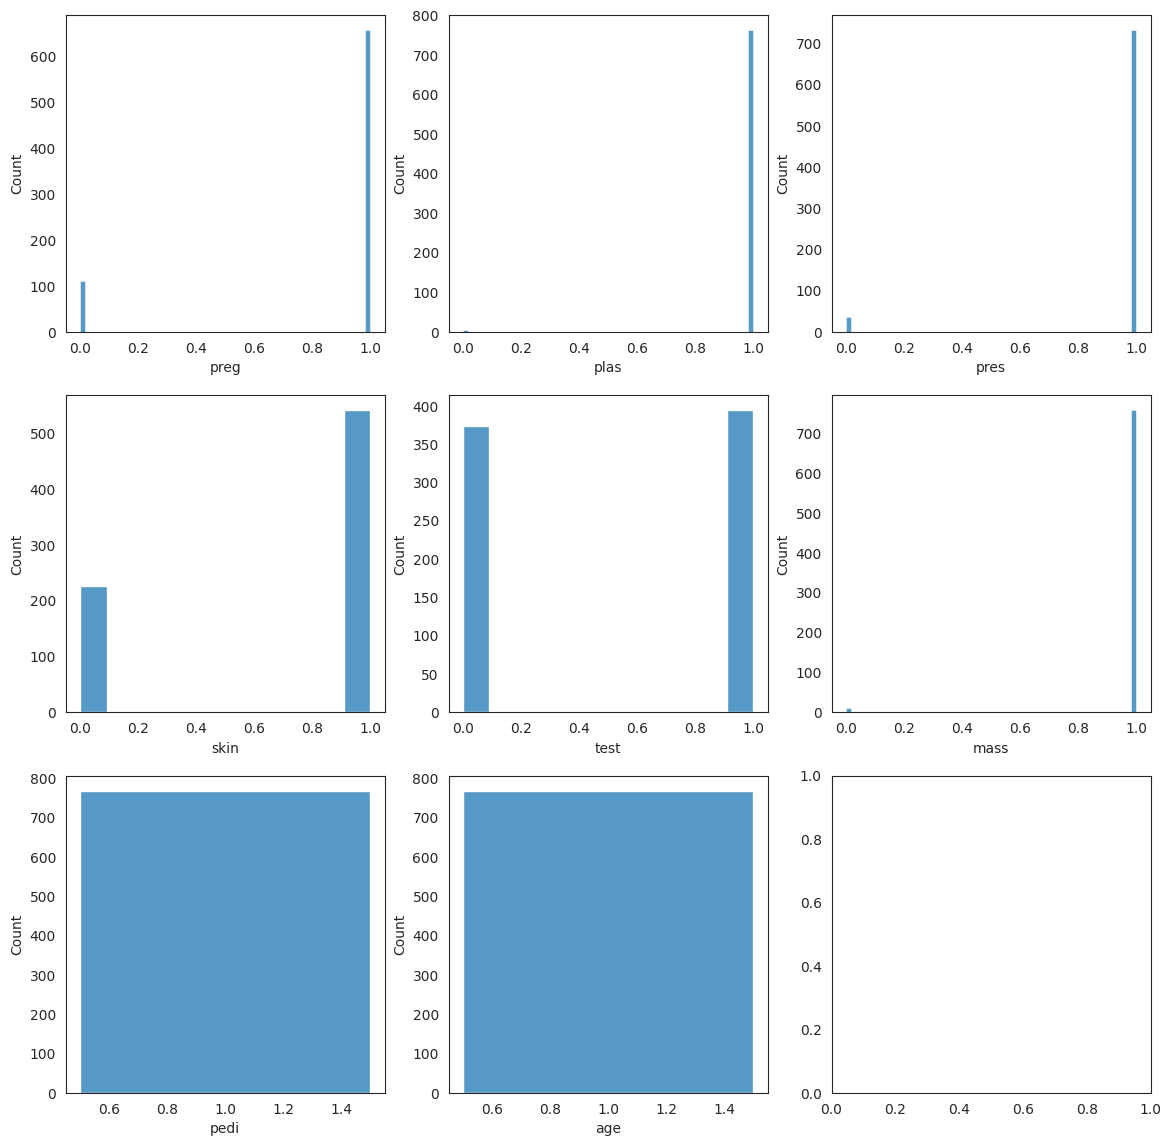

In [44]:

f, axes = plt.subplots(3, 3, figsize=(14, 14))
sns.histplot(transform_df["preg"], ax=axes[0, 0])
sns.histplot(transform_df["plas"], ax=axes[0, 1])
sns.histplot(transform_df["pres"], ax=axes[0, 2])
sns.histplot(transform_df["skin"], ax=axes[1, 0])
sns.histplot(transform_df["test"], ax=axes[1, 1])
sns.histplot(transform_df["mass"], ax=axes[1, 2])
sns.histplot(transform_df["pedi"], ax=axes[2, 0])
sns.histplot(transform_df["age"], ax=axes[2, 1])


Al utilizar binarizer() todos la inforamcion importante se pierde, esta funcion es util cuando la variable objetivo es numerica continua digamos;  Edad → mayor de 50 años = 1, sino = 0 || Glucosa → mayor de 140 = 1, sino = 0

<a id="section25"></a>
## <font color="#004D7F"> 2.5. Box-Cox</font>

En ocasiones los atributos representan el llamado sesgo o inclinación, que es cuando un atributo tiene una distribución similar a la Gaussiana pero esta se encuentra desplazada. Para este tipo de casos, se utiliza la transformación Box-Cox, la cual asume que todos los valores son positivos, que lo que realiza es el sesgo y hacer más Gaussiana la distribución de este atributo. Nótese que aplicamos la transformación sólo a dos atributos que parecen tener un sesgo.

<Figure size 640x480 with 0 Axes>

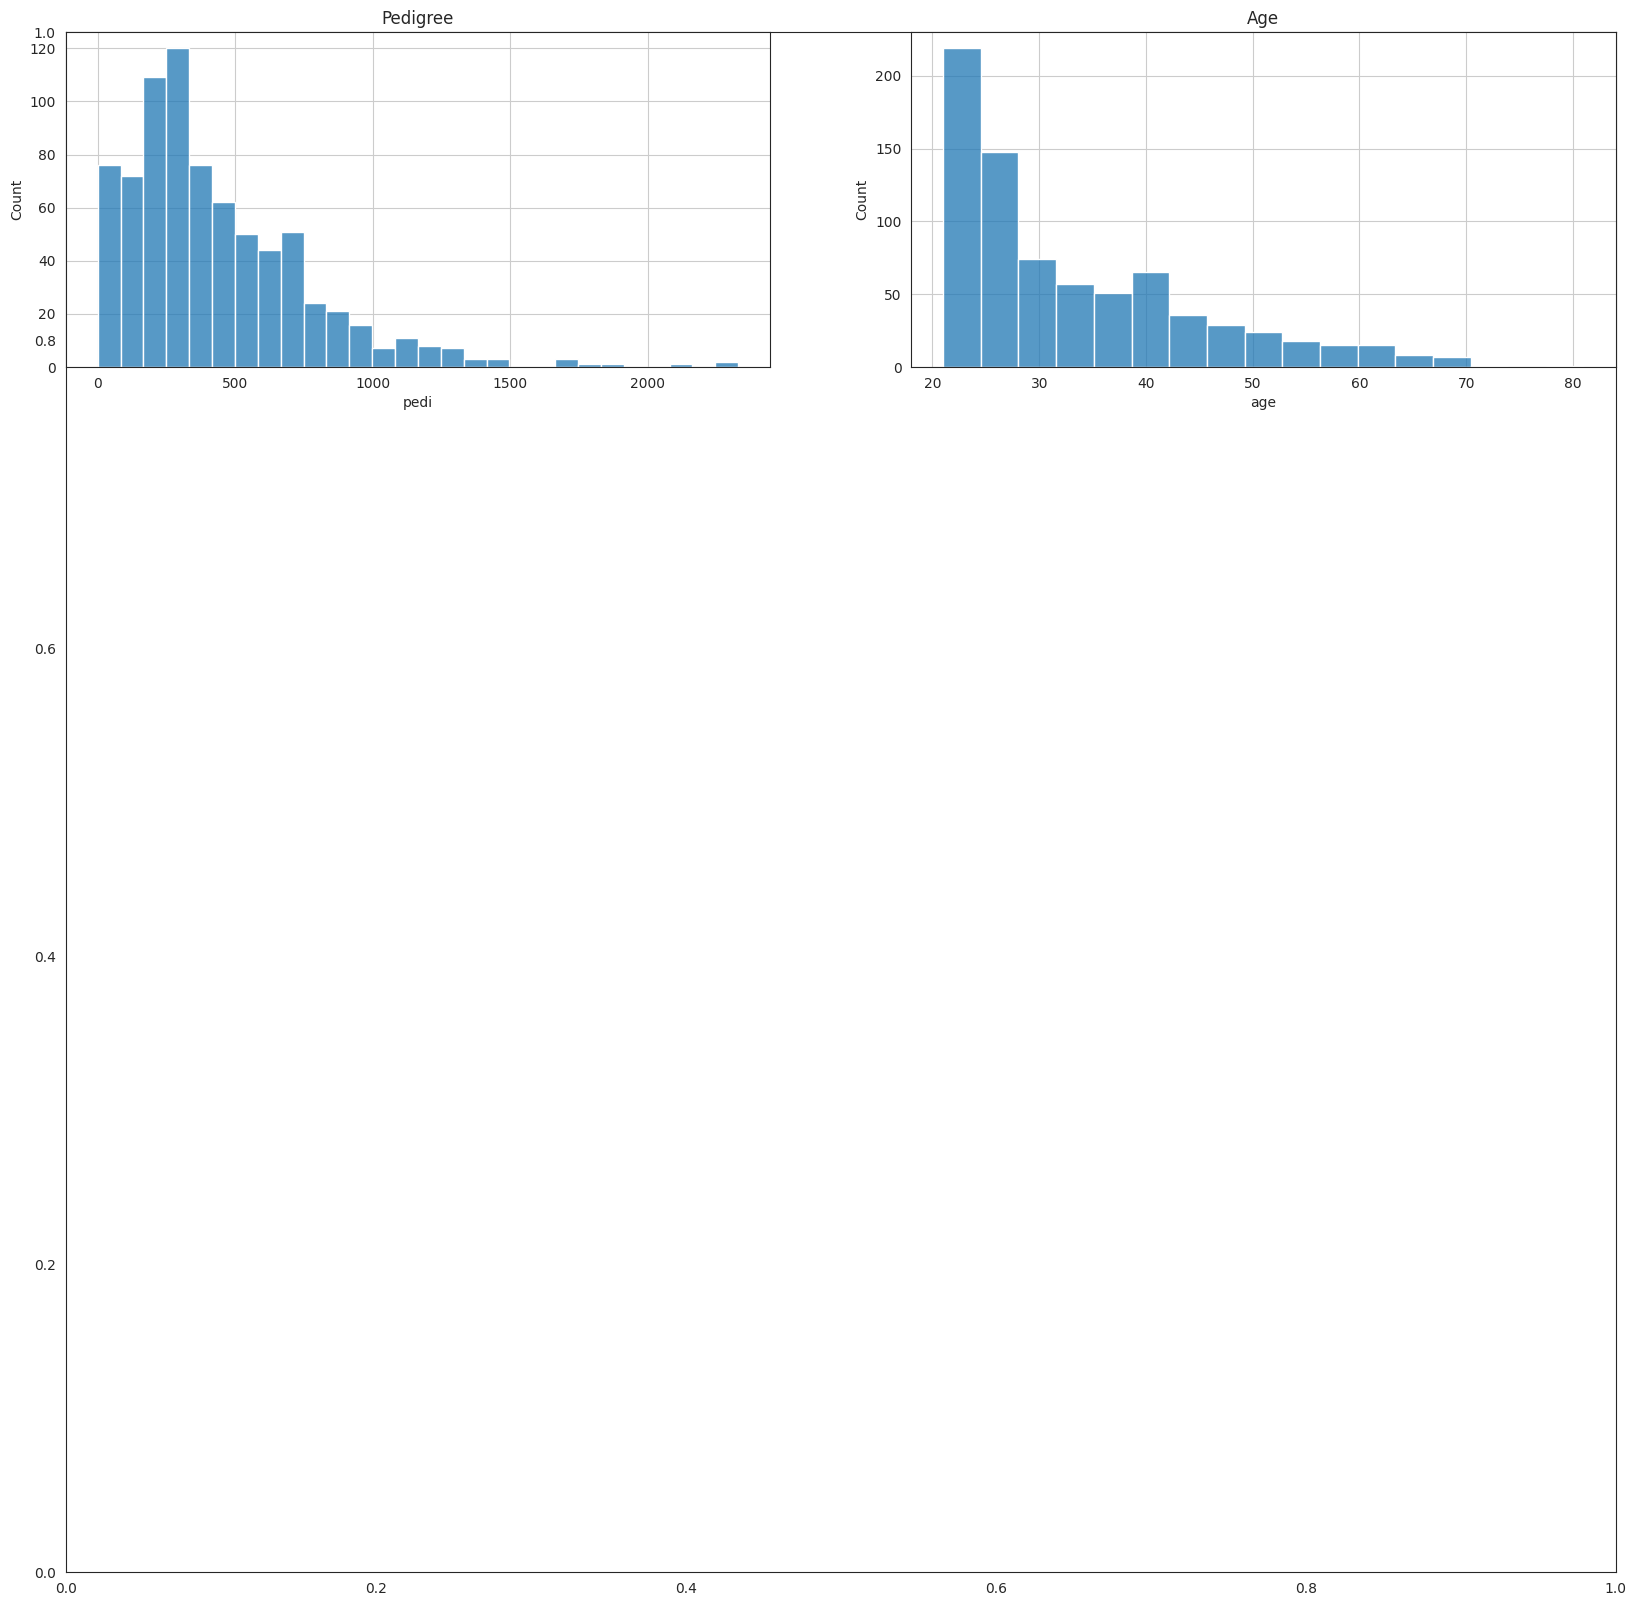

In [32]:
# Univariate Histograms
plt.figure(1)
plt.subplots(figsize=(20,20))
plt.subplot(421)
sns.histplot(data['pedi'])
plt.title('Pedigree')
plt.grid(True)
plt.subplot(422)
sns.histplot(data['age'])
plt.title('Age')
plt.grid(True)
plt.show()


Se muestran dos histogramas importantes (pedi 'diabetes pedigree function' & age)

Como vemos, ese sesgo tenemos que corregirlo y para ello utilizaremos la clase [PowerTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PowerTransformer.html). Una vez realizada la transformación podemos ver como se encuentra corregido el sesgo inicial de ambas características.

In [35]:
# Box-Cox Transform
from sklearn.preprocessing import PowerTransformer

# extract features with skew
skew_cols = ['pedi', 'age']

# instatiate 
skl_boxcox = PowerTransformer(method='box-cox')

# Fit the data to the powertransformer
skl_boxcox.fit(data[skew_cols])

# Lets get the Lambdas that were found
calc_lambdas_bc = skl_boxcox.lambdas_
print(calc_lambdas_bc)

# Transform the data 
boxcox_data = skl_boxcox.transform(data[skew_cols])

# Pass the transformed data into a new dataframe 
boxcox_df = pd.DataFrame(boxcox_data, columns=skew_cols)

# Pass to the original dataframe the transform columns
data_rest = data.drop(columns=skew_cols)

# Concatenar ambos dataframes
df_data = pd.concat([data_rest, boxcox_df], axis=1)

# Pasa el último elemento al primero de la lista (2 veces)
cols = df_data.columns.tolist()
cols.insert(0, cols.pop())
cols.insert(0, cols.pop())

# Sobreescribimos
df_data = df_data[cols]
df_data

[ 0.469 -1.094]


,pedi,age,preg,plas,pres,skin,test,mass,class
0,0.717716,1.362797,6,148,72,35,0,33.6,1
1,0.018767,0.127990,1,85,66,29,0,26.6,0
2,0.814658,0.231506,8,183,64,0,0,23.3,1
3,-0.638772,-1.483064,1,89,66,23,94,28.1,0
4,3.167741,0.328461,0,137,40,35,168,43.1,1
...,...,...,...,...,...,...,...,...,...
763,-0.621159,1.764261,10,101,76,48,180,32.9,0
764,-2.130656,-0.366775,2,122,70,27,0,36.8,0
765,-0.328074,0.017237,5,121,72,23,112,26.2,0
766,0.012785,1.236934,1,126,60,0,0,30.1,1


Aplica box-cox(transf matematica que usa para que los datos tengan una mejor distribucion, los modelos funcionan mucho mejor con distribuciones normales)

<Figure size 640x480 with 0 Axes>

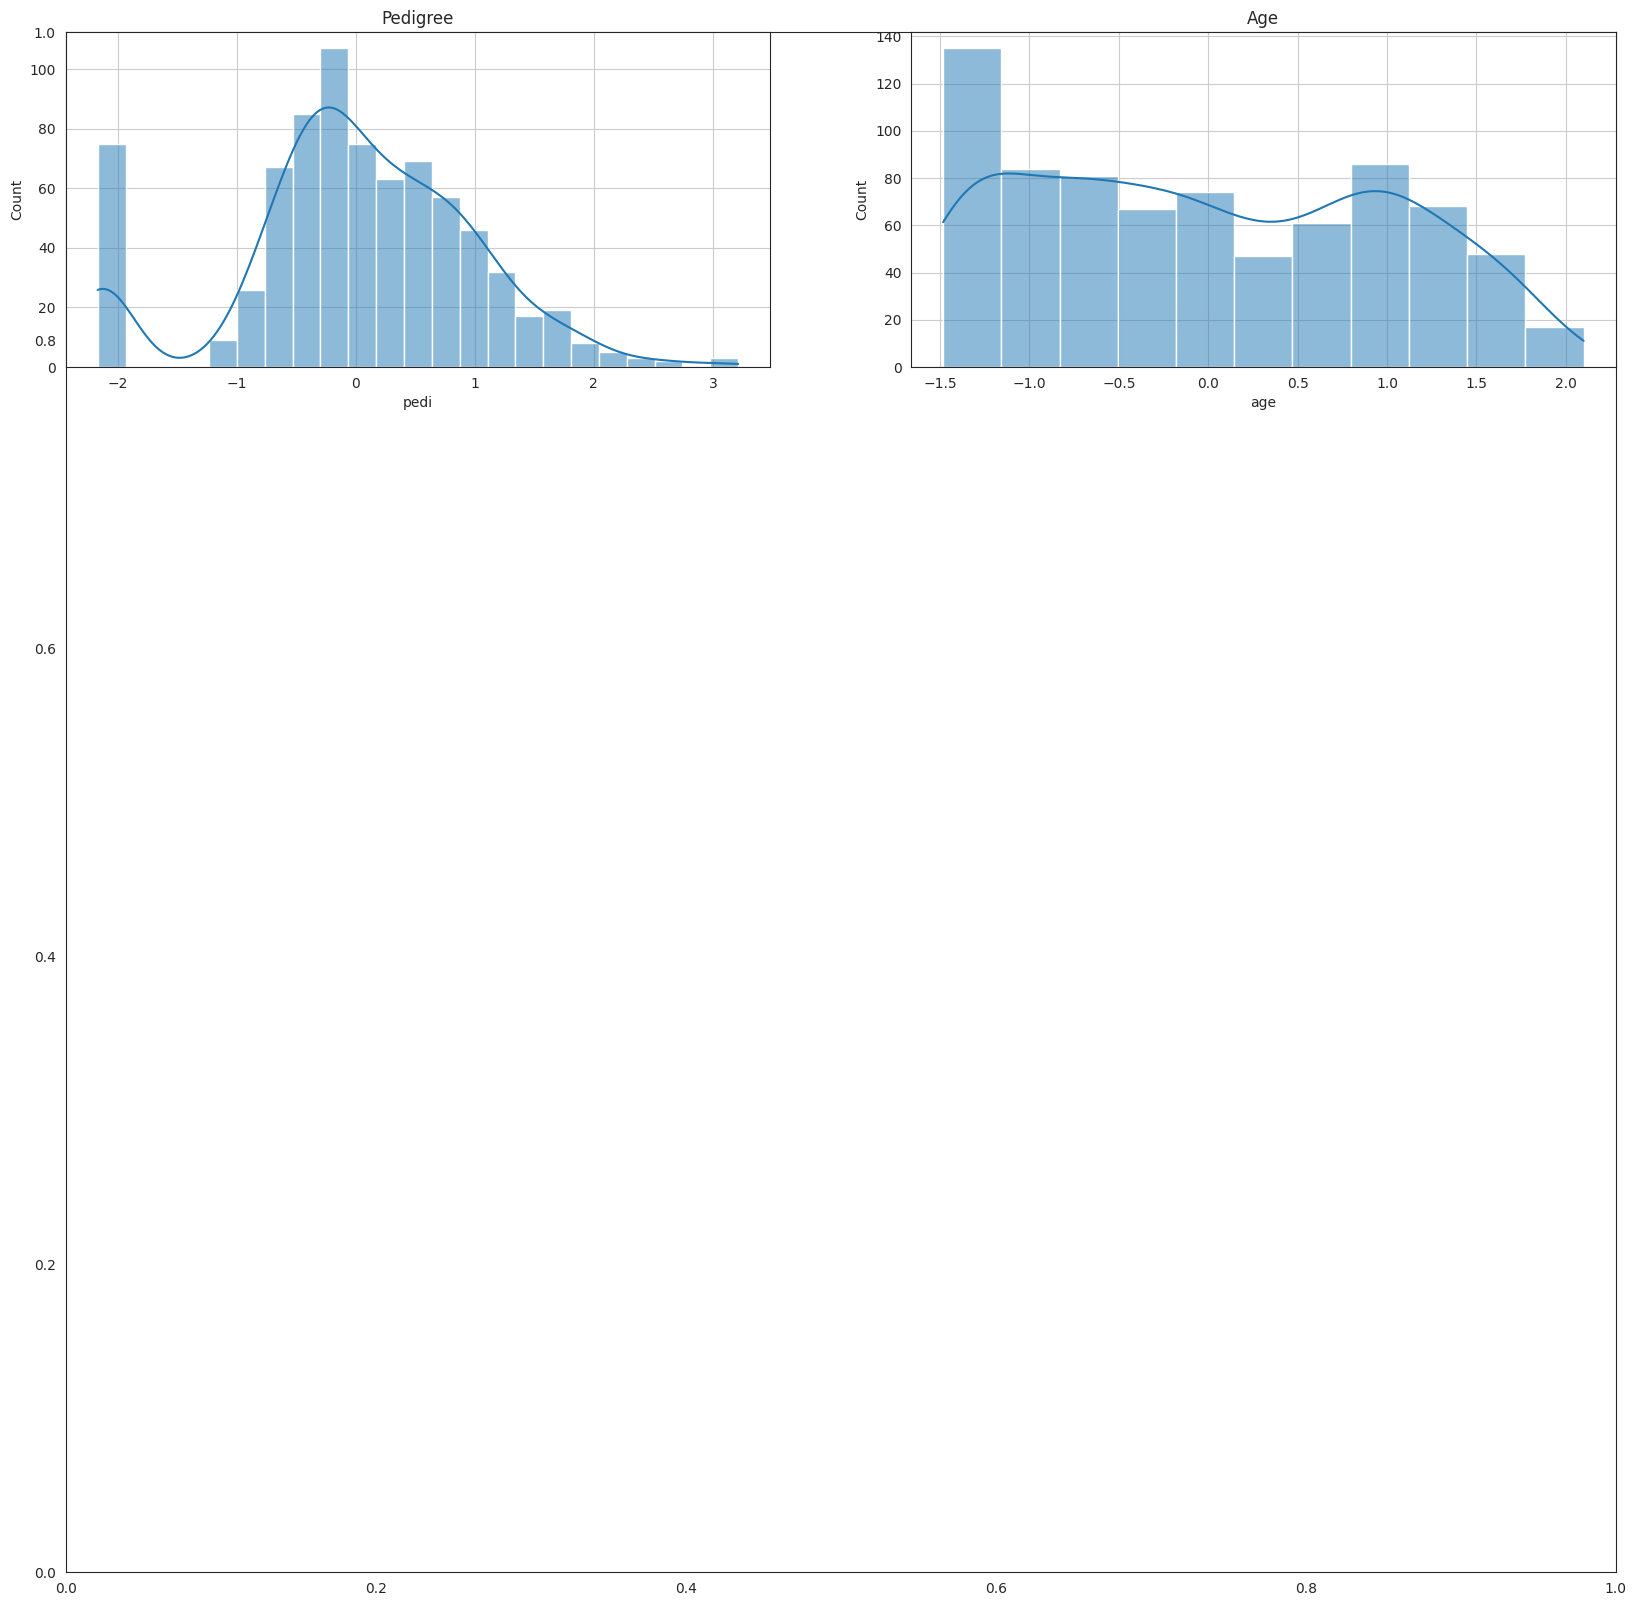

In [36]:
# Univariate Histograms
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

plt.figure(1)
plt.subplots(figsize=(20,20))
plt.subplot(421)
sns.histplot(df_data['pedi'], kde=True)
plt.title('Pedigree')
plt.grid(True)
plt.subplot(422)
sns.histplot(df_data['age'], kde=True)
plt.title('Age')
plt.grid(True)
plt.show()

al utilizar este metodo los datos se ven mas simetricos que en la version anterior, no hay sesgo muy marcado hacia la derecha como en el anterior

### Yeo Johnson

<a id="section26"></a>
## <font color="#004D7F"> 2.6. Yeo-Johnson</font>

La transformación de Yeo-Johnson es otra transformación de potencia como Box-Cox, pero soporta valores en bruto (sin procesar) que son iguales a cero y negativos. Para utilizar esta transformación únicamente tenemos que poner en la propiedad `method` de la clase `PowerTransformer` el valor `yeo-johnson` o directamente no poner `method` ya que por defecto utiliza esta transoformación.

In [37]:
# Yeo-Johnson Transform
from sklearn.preprocessing import PowerTransformer

# extract features with skew
skew_cols = ['pedi', 'age']

# instatiate 
skl_yeojohnson = PowerTransformer(method='yeo-johnson')

# Fit the data to the powertransformer
skl_yeojohnson.fit(data[skew_cols])

# Lets get the Lambdas that were found
calc_lambdas_yo = skl_yeojohnson.lambdas_
print(calc_lambdas_yo)

# Transform the data 
yeojohnson_data = skl_yeojohnson.transform(data[skew_cols])

# Pass the transformed data into a new dataframe 
yeojohnson_df = pd.DataFrame(yeojohnson_data, columns=skew_cols)

# Pass to the original dataframe the transform columns
data_rest = data.drop(columns=skew_cols)

# Concatenar ambos dataframes
df_data = pd.concat([data_rest, yeojohnson_df], axis=1)

# Pasa el último elemento al primero de la lista (2 veces)
cols = df_data.columns.tolist()
cols.insert(0, cols.pop())
cols.insert(0, cols.pop())

# Sobreescribimos
df_data = df_data[cols]
df_data

[ 0.48 -1.15]


,pedi,age,preg,plas,pres,skin,test,mass,class
0,0.720862,1.364180,6,148,72,35,0,33.6,1
1,0.005392,0.126452,1,85,66,29,0,26.6,0
2,0.820468,0.230161,8,183,64,0,0,23.3,1
3,-0.662166,-1.480075,1,89,66,23,94,28.1,0
4,3.258044,0.327328,0,137,40,35,168,43.1,1
...,...,...,...,...,...,...,...,...,...
763,-0.644375,1.765331,10,101,76,48,180,32.9,0
764,-2.074512,-0.368619,2,122,70,27,0,36.8,0
765,-0.347546,0.015535,5,121,72,23,112,26.2,0
766,-0.000709,1.238144,1,126,60,0,0,30.1,1


Aqui esta aplicando Yeo Johnson version >> Box-Cox, no funciona con 0 y negativos, >> flexible, 

<Figure size 640x480 with 0 Axes>

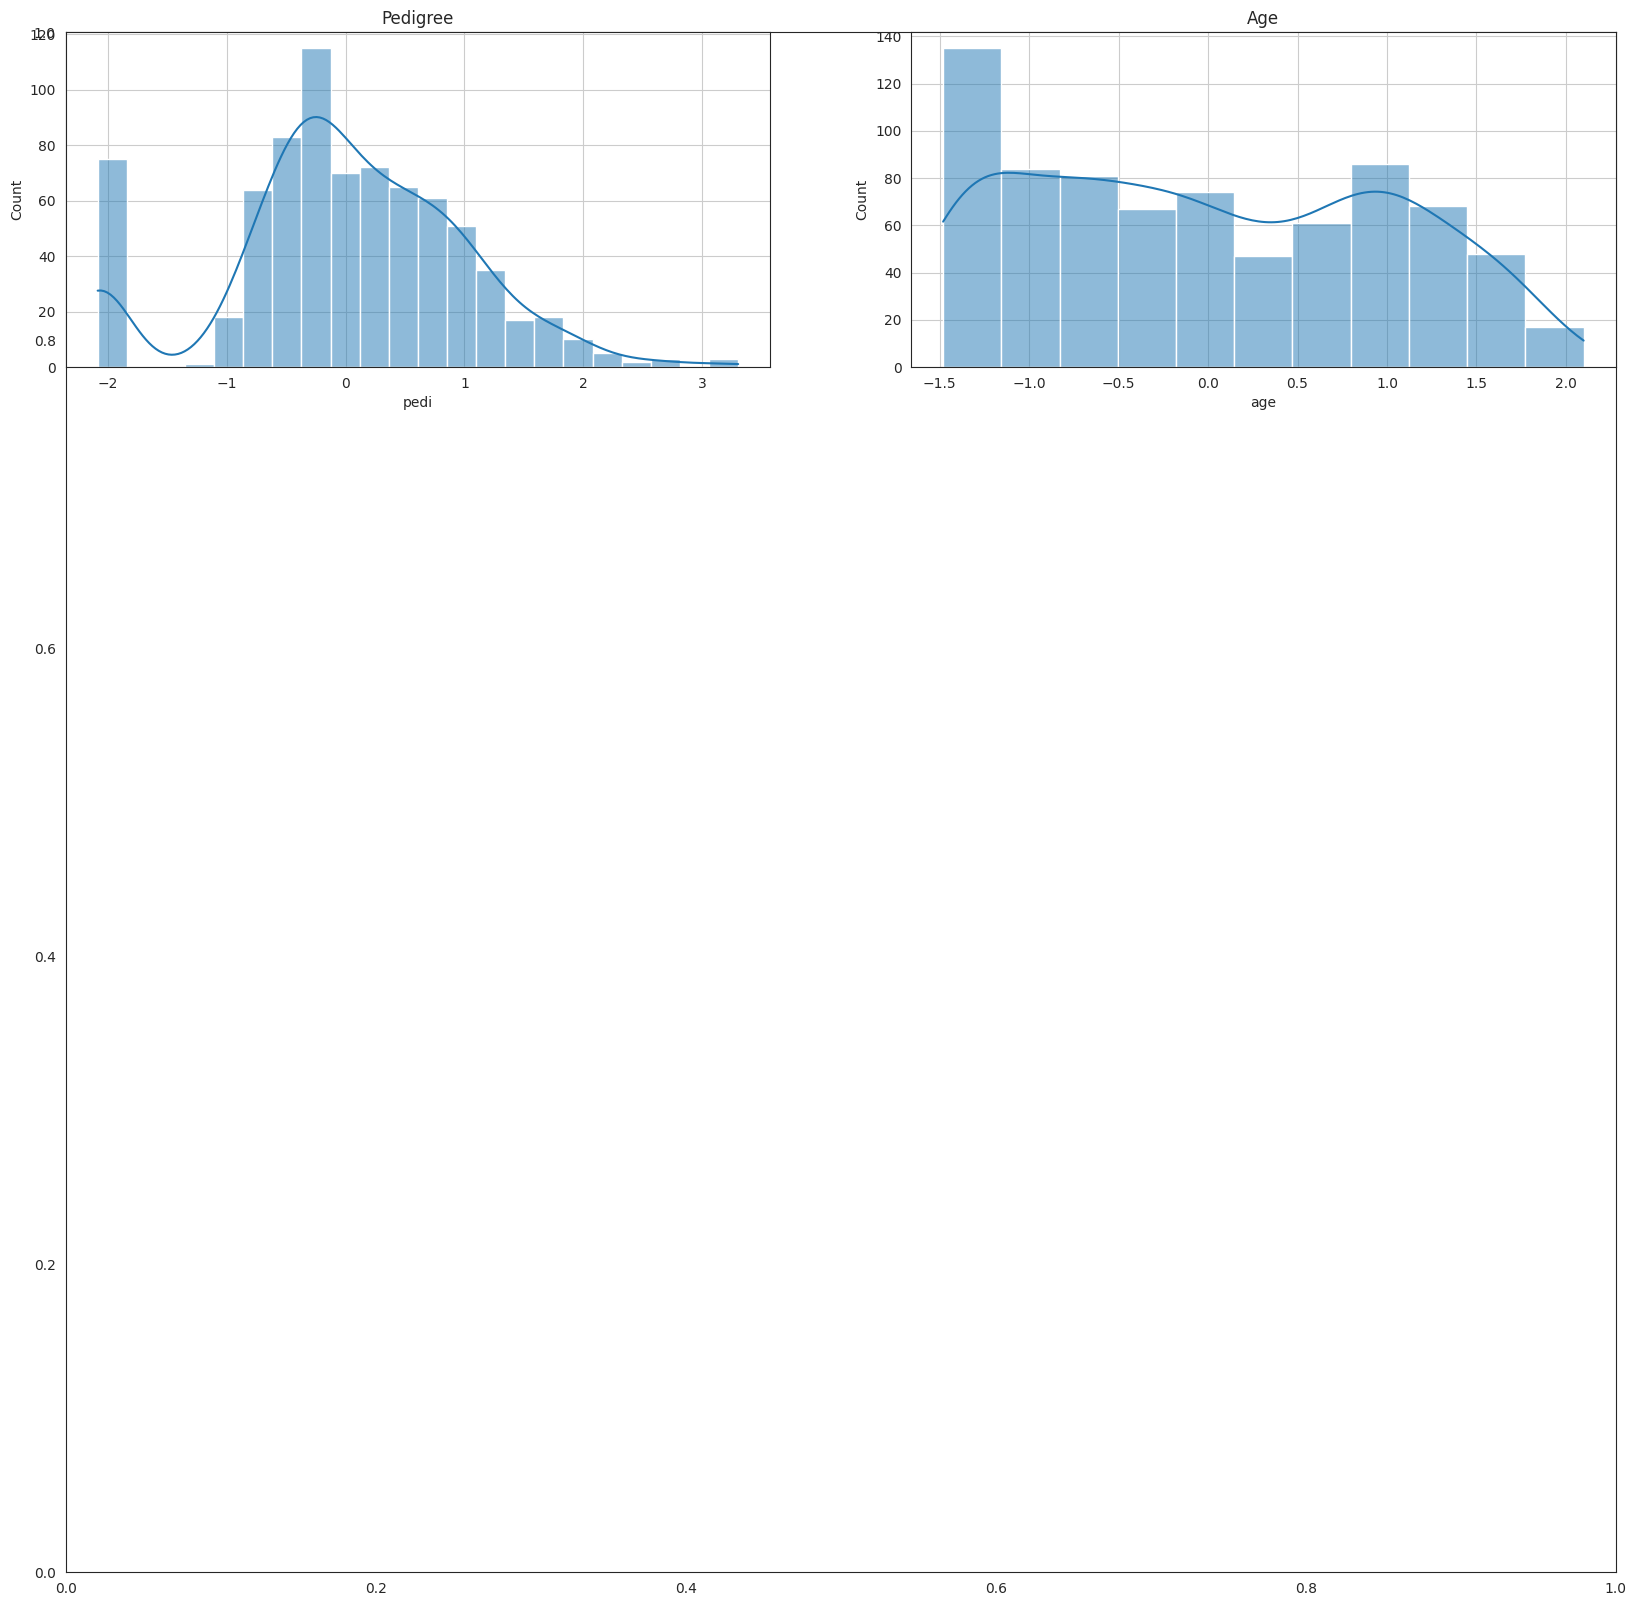

In [39]:
# Univariate Histograms
plt.figure(1)
plt.subplots(figsize=(20,20))
plt.subplot(421)
sns.histplot(df_data['pedi'], kde=True)
plt.title('Pedigree')
plt.grid(True)
plt.subplot(422)
sns.histplot(df_data['age'], kde=True)
plt.title('Age')
plt.grid(True)
plt.show()

Muestra los graficos, muy similar a box-cox 

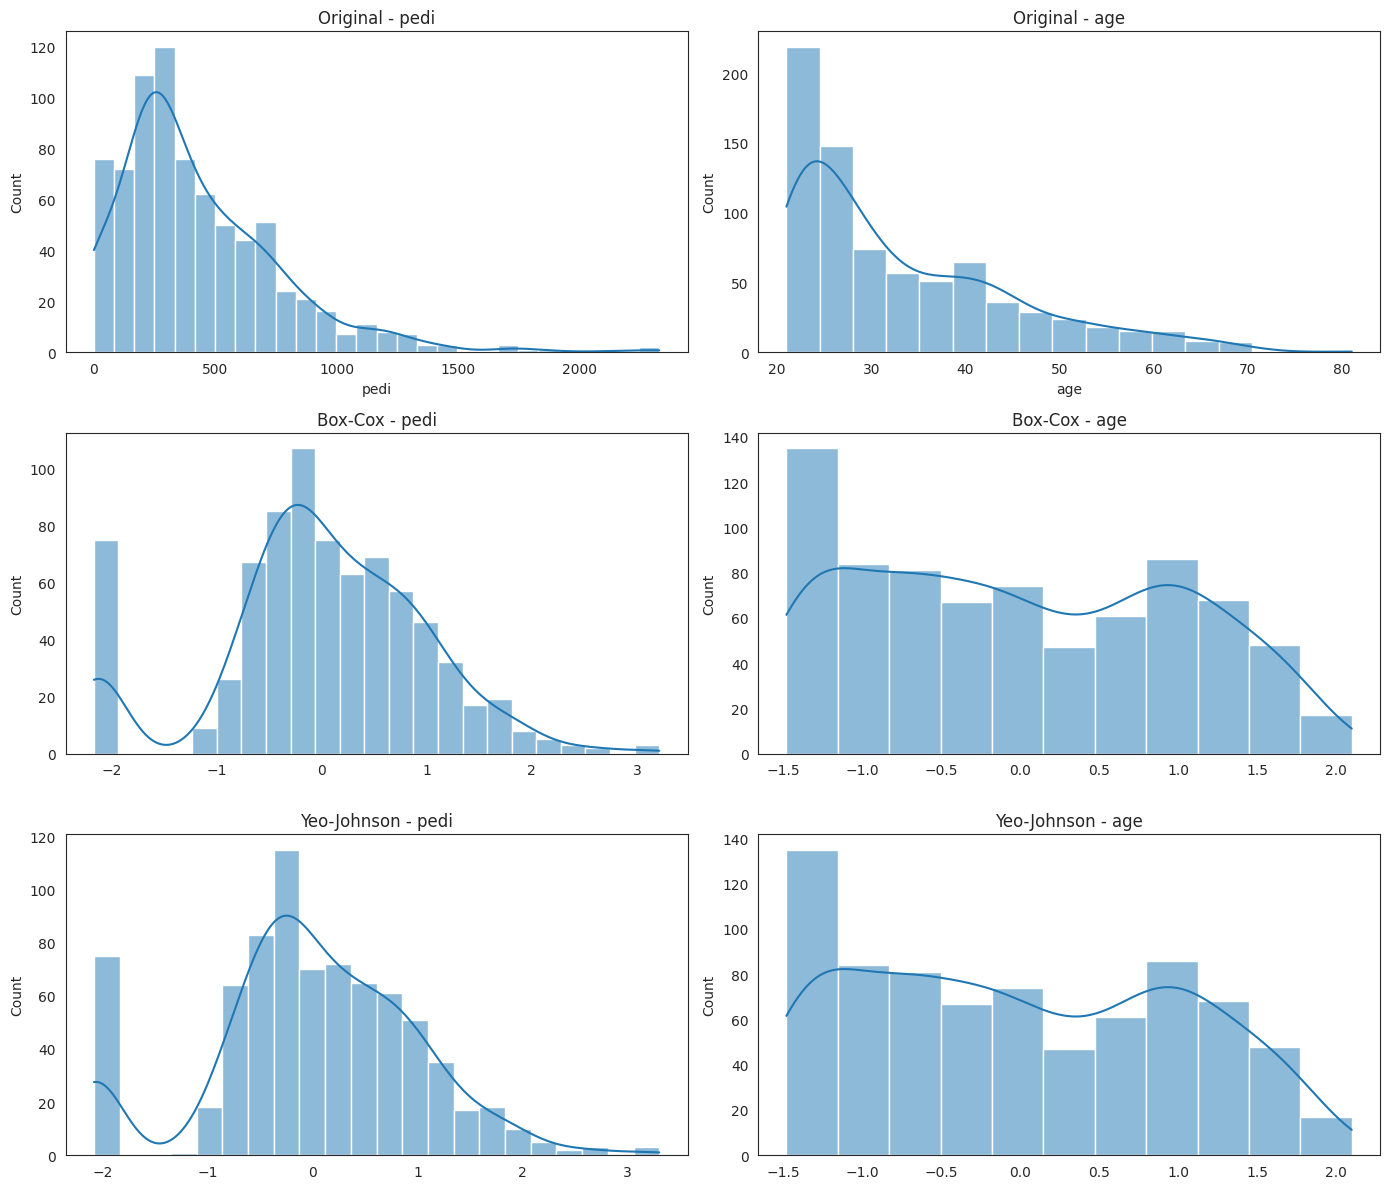

In [49]:
from sklearn.preprocessing import PowerTransformer
import seaborn as sns
import matplotlib.pyplot as plt

cols = ['pedi', 'age']

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

# Original
for i, col in enumerate(cols):
    sns.histplot(data[col], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f'Original - {col}')

# Box-Cox
pt_bc = PowerTransformer(method='box-cox')
data_bc = pt_bc.fit_transform(data[cols])
for i, col in enumerate(cols):
    sns.histplot(data_bc[:, i], kde=True, ax=axes[1, i])
    axes[1, i].set_title(f'Box-Cox - {col}')

# Yeo-Johnson
pt_yj = PowerTransformer(method='yeo-johnson')
data_yj = pt_yj.fit_transform(data[cols])
for i, col in enumerate(cols):
    sns.histplot(data_yj[:, i], kde=True, ax=axes[2, i])
    axes[2, i].set_title(f'Yeo-Johnson - {col}')

plt.tight_layout()
plt.show()

Muestra los tres metodos, BoxCox & Yeo J. son iguales, no hay diferencia aparente...

<a id="section26"></a>
### <font color="#004D7F"> Coeficiente Box-Cox y Yeo-Johnson</font>

Estas transforamciones surgen ya que en determinadas ocasionas se utilizan una transformación logarítmica o de raíz cuadrada a los datos pero sin saber muy bien cual de los dos tendrá una mejor incidencia. Estas dos transformaciones realizan ese análisis y establece la mejor transforamción para sus datos. 

Podemos usar una versión generalizada de la transformación que encuentre un parámetro (lambda) que mejor transforme una variable en una distribución de probabilidad gaussiana (si logarítmica o raíz cuadrada, por ejemplo). Hay dos enfoques populares para tales transformaciones automáticas de energía; son:

Si nos hemos fijado `PowerTransform` tiene una propiedad llamada `lambdas_`, a menudo denominado lambda, se usa para controlar la naturaleza de la transformación. A continuación se presentan algunos valores comunes para _lambda:_
 * _lambda = -1_ es una transformación recíproca.
 * _lambda = -0.5_ es una transformación de raíz cuadrada recíproca.
 * _lambda = 0.0_ es una transformación logarítmica.
 * _lambda = 0.5_ es una transformación de raíz cuadrada.
 * _lambda = 1.0_ no es una transformación.

Veamos el coeficiente de de las dos variables son:

In [40]:
print(f"Lambda de Box-Cox: {calc_lambdas_bc}")
print(f"Lambda de Yeo-Johnson: {calc_lambdas_yo}")

Lambda de Box-Cox: [ 0.469 -1.094]
Lambda de Yeo-Johnson: [ 0.48 -1.15]


Podemos observar que a la primera variable le ha realizado una raíz cudrada recíproca y a la segunda una transforamción recíproca.

<div style="text-align: right"> <font size=5>
    <a href="#indice"><i class="fa fa-arrow-circle-up" aria-hidden="true" style="color:#004D7F"></i></a>
</font></div>

---

<div style="text-align: right"> <font size=6><i class="fa fa-coffee" aria-hidden="true" style="color:#004D7F"></i> </font></div>

### Flujo de Preprocesamiento - Dataset Diabetes

```
Datos Originales (Pima Diabetes Dataset)
        │
        ▼
Exploración Inicial
   - Histogramas
   - Análisis de distribuciones
        │
        ▼
Identificar Variable Objetivo
   → outcome (0 = No Diabetes, 1 = Sí Diabetes)
        │
        ▼
Decisión: ¿Escalar los datos?
        │
        ├─► Sí ──► StandardScaler (Recomendado)
        │             │
        │             ▼
        │       Datos Estandarizados (media=0, std=1)
        │
        ▼
¿Hay variables muy sesgadas? (pedi, test, etc.)
        │
        ├─► Sí ──► Yeo-Johnson (Recomendado)
        │             │
        │             ▼
        │       Datos Transformados
        │
        ▼
DataFrame Final Preparado (X_scaled + y)
        │
        ▼
Dividir datos
   → train_test_split
        │
        ▼
Entrenamiento de Modelo

  (KNN, Regresión Logística, SVM, etc.)